# GNN Depth vs. Robust Expressivity: Oversmoothing Study

Supports **GIN** and **GCN** — set `ARCH` in the Setup cell.


**Core question:** Does increasing depth $L$ collapse the model-based margin $\hat{\gamma}_{f(A)}$ through oversmoothing, and does this directly predict alignment failure under edge perturbations?

$$\hat{\gamma}_{f(A)} = \min_{i \neq j} \|[f(A)]_i - [f(A)]_j\|$$

Robust node-level expressivity: the GNN survives perturbation $k$ if $\|f(A) - f(A')\| < \hat{\gamma}_{f(A)}$.

**Graph families** (set `GRAPH_TYPES` in the Setup cell). The full train + evaluate pipeline is repeated per family:

| Key | Family | Notes |
|---|---|---|
| `ER` | Erdős–Rényi | edges i.i.d. w.p. `ER_PROB` |
| `BA` | Barabási–Albert | preferential attachment, `BA_M` edges per new node (heavy-tailed degrees) |
| `SBM` | Stochastic block model | blocks `SBM_SIZES`, intra/inter prob. `SBM_P_IN` / `SBM_P_OUT` |
| `WS` | Watts–Strogatz | ring lattice of degree `WS_K`, rewired w.p. `WS_P` (small world) |
| `ENZYMES` | TUDataset ENZYMES | 600 real protein graphs (~33 nodes avg), fixed train/test split of graphs |

The synthetic families use `N_NODES` nodes and are tuned to a mean degree of about 12, matching ER with `ER_PROB=0.4`.

In [1]:
%%capture
!pip install torch_geometric networkx

## 0. Setup

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINConv, GCNConv
from torch_geometric.data import Data

import numpy as np
import networkx as nx
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import random, warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

# ── Architecture choice ───────────────────────────────────────────────────────
ARCH = 'GIN'   # 'GIN' or 'GCN'

# ── Node feature choice ──────────────────────────────────────────────────────
# 'degree'       : node feature = degree of the *input* graph (recomputed from
#                  the perturbed graph at inference time, not the clean graph).
# 'all_ones'     : constant all-ones feature vector, invariant to perturbation.
# 'random_fixed' : a random vector drawn once per node when the clean graph is
#                  sampled; held fixed (acts as a node id) under edge perturbation.
# (For ENZYMES the dataset's own node attributes are ignored; the same
#  FEATURE_TYPE is used so all families are directly comparable.)
FEATURE_TYPE = 'all_ones'   # 'degree' | 'all_ones' | 'random_fixed'

# ── Graph family choice ───────────────────────────────────────────────────────
# The full depth sweep (x all seeds) is repeated per family.
GRAPH_TYPES  = ['ER', 'BA', 'SBM', 'WS', 'ENZYMES']
# ER      : Erdos-Renyi            — edge iid with prob. ER_PROB
# BA      : Barabasi-Albert        — preferential attachment, BA_M edges per new node
# SBM     : Stochastic block model — blocks SBM_SIZES, prob. SBM_P_IN inside / SBM_P_OUT across
# WS      : Watts-Strogatz         — ring lattice (degree WS_K) rewired w.p. WS_P
# ENZYMES : real protein graphs from TUDataset (variable size)
GRAPH_COLORS = {'ER': 'tab:blue', 'BA': 'tab:red', 'SBM': 'tab:green',
                'WS': 'tab:purple', 'ENZYMES': 'tab:brown'}

# ── Hyperparameters ──────────────────────────────────────────────────────────
N_NODES      = 30
ER_PROB      = 0.4                 # mean degree ≈ 0.4 * 29 ≈ 11.6
BA_M         = 6                   # mean degree ≈ 2 * BA_M ≈ 12 (minus seed-star correction)
SBM_SIZES    = [10, 10, 10]        # must sum to N_NODES
SBM_P_IN     = 0.9                 # mean degree ≈ 9*0.9 + 20*0.2 ≈ 12.1
SBM_P_OUT    = 0.2
WS_K         = 12                  # mean degree = WS_K
WS_P         = 0.1
ENZYMES_ROOT       = 'data/TUDataset'
ENZYMES_MIN_NODES  = 5             # drop tiny graphs (margin is degenerate for n<2)
ENZYMES_TEST_FRAC  = 0.2           # fraction of graphs held out for evaluation
ENZYMES_SPLIT_SEED = 0             # fixed graph-level train/test split
FEAT_DIM     = 1
HIDDEN_DIM   = 64
EMBED_DIM    = 32
TRAIN_STEPS  = 1000
LR           = 5e-4
N_TEST       = 80
K_VALUES     = [0, 1, 2, 3, 4, 5, 6, 8]
FIXED_MARGIN = 0.5
DEPTH_VALUES = [3,4,5,6]
assert sum(SBM_SIZES) == N_NODES

# ── Random-seed replication ──────────────────────────────────────────────────
# The whole train+evaluate pipeline is repeated once per seed in SEEDS; results
# are then aggregated (mean ± std) across seeds at every depth.
N_SEEDS = 5
SEEDS   = list(range(N_SEEDS))

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 130})
CMAP_L = cm.viridis

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Using device: cuda


## 1. Graph Generation and Perturbation

In [3]:
def compute_features(A, feat_dim, feature_type, rng):
    n = A.shape[0]
    if feature_type == 'degree':
        # degree of the graph actually passed in (clean or perturbed)
        degree = (A.sum(axis=1, keepdims=True) / n).astype(np.float32)
        if feat_dim > 1:
            degree = np.concatenate(
                [degree, np.zeros((n, feat_dim - 1), dtype=np.float32)], axis=1)
        return degree
    elif feature_type == 'all_ones':
        return np.ones((n, feat_dim), dtype=np.float32)
    elif feature_type == 'random_fixed':
        return rng.randn(n, feat_dim).astype(np.float32)
    else:
        raise ValueError(f'Unknown FEATURE_TYPE: {feature_type}')


def _nx_seed(seed):
    return int(seed) if seed is not None else None


def _finish(A, feat_dim, feature_type, seed):
    rng   = np.random.RandomState(seed) if seed is not None else np.random
    feats = compute_features(A, feat_dim, feature_type, rng)
    return A, feats


def sample_er_graph(n=N_NODES, p=ER_PROB, feat_dim=FEAT_DIM, seed=None,
                    feature_type=FEATURE_TYPE, split=None):
    rng = np.random.RandomState(seed) if seed is not None else np.random
    A = np.zeros((n, n), dtype=np.float32)
    for i in range(n):
        for j in range(i + 1, n):
            if rng.rand() < p:
                A[i, j] = A[j, i] = 1.0
    feats = compute_features(A, feat_dim, feature_type, rng)
    return A, feats


def sample_ba_graph(n=N_NODES, m=BA_M, feat_dim=FEAT_DIM, seed=None,
                    feature_type=FEATURE_TYPE, split=None):
    # Barabasi-Albert preferential attachment: each new node attaches to m existing nodes
    G = nx.barabasi_albert_graph(n, m, seed=_nx_seed(seed))
    A = nx.to_numpy_array(G, nodelist=range(n)).astype(np.float32)
    return _finish(A, feat_dim, feature_type, seed)


def sample_sbm_graph(sizes=SBM_SIZES, p_in=SBM_P_IN, p_out=SBM_P_OUT,
                     feat_dim=FEAT_DIM, seed=None, feature_type=FEATURE_TYPE,
                     split=None):
    # Stochastic block model: dense within blocks, sparse across blocks
    B     = len(sizes)
    probs = [[p_in if a == b else p_out for b in range(B)] for a in range(B)]
    G = nx.stochastic_block_model(sizes, probs, seed=_nx_seed(seed))
    n = sum(sizes)
    A = nx.to_numpy_array(G, nodelist=range(n)).astype(np.float32)
    return _finish(A, feat_dim, feature_type, seed)


def sample_ws_graph(n=N_NODES, k=WS_K, p=WS_P, feat_dim=FEAT_DIM, seed=None,
                    feature_type=FEATURE_TYPE, split=None):
    # Watts-Strogatz small-world: ring lattice of degree k, edges rewired w.p. p
    G = nx.watts_strogatz_graph(n, k, p, seed=_nx_seed(seed))
    A = nx.to_numpy_array(G, nodelist=range(n)).astype(np.float32)
    return _finish(A, feat_dim, feature_type, seed)


# ── ENZYMES (real graphs) ────────────────────────────────────────────────────
_ENZYMES_CACHE = {}

def load_enzymes():
    # Load ENZYMES once, convert to dense symmetric adjacency matrices, and make
    # a fixed graph-level train/test split so evaluation uses unseen graphs.
    if not _ENZYMES_CACHE:
        from torch_geometric.datasets import TUDataset
        ds = TUDataset(root=ENZYMES_ROOT, name='ENZYMES')
        graphs = []
        for d in ds:
            n = int(d.num_nodes)
            if n < ENZYMES_MIN_NODES:
                continue
            A  = np.zeros((n, n), dtype=np.float32)
            ei = d.edge_index.cpu().numpy()
            A[ei[0], ei[1]] = 1.0
            A = np.maximum(A, A.T)
            np.fill_diagonal(A, 0.0)
            graphs.append(A)
        perm   = np.random.RandomState(ENZYMES_SPLIT_SEED).permutation(len(graphs))
        n_test = int(round(ENZYMES_TEST_FRAC * len(graphs)))
        _ENZYMES_CACHE['test']  = [graphs[i] for i in perm[:n_test]]
        _ENZYMES_CACHE['train'] = [graphs[i] for i in perm[n_test:]]
    return _ENZYMES_CACHE


def sample_enzymes_graph(feat_dim=FEAT_DIM, seed=None, feature_type=FEATURE_TYPE,
                         split='train'):
    # split='train': random draw from the training graphs (global np.random, so it
    #                is reproducible under train_model's seeding).
    # split='test' : deterministic, graph index = seed mod #test graphs.
    pool = load_enzymes()[split]
    if split == 'test' and seed is not None:
        idx = int(seed) % len(pool)
    else:
        rng = np.random.RandomState(seed) if seed is not None else np.random
        idx = rng.randint(len(pool))
    A = pool[idx].copy()
    return _finish(A, feat_dim, feature_type, seed)


GRAPH_GENERATORS = {
    'ER':      sample_er_graph,
    'BA':      sample_ba_graph,
    'SBM':     sample_sbm_graph,
    'WS':      sample_ws_graph,
    'ENZYMES': sample_enzymes_graph,
}


def sample_graph(graph_type, seed=None, split='train', **kwargs):
    # `split` only matters for dataset-backed families (ENZYMES); synthetic
    # generators draw fresh graphs either way.
    return GRAPH_GENERATORS[graph_type](seed=seed, split=split, **kwargs)


def perturb_graph(A, feats, k, seed=None, feature_type=FEATURE_TYPE):
    rng        = np.random.RandomState(seed) if seed is not None else np.random
    n          = A.shape[0]
    Ap         = A.copy()
    rows, cols = np.triu_indices(n, k=1)
    chosen     = rng.choice(len(rows), min(k, len(rows)), replace=False)
    for idx in chosen:
        r, c = rows[idx], cols[idx]
        Ap[r, c] = Ap[c, r] = 1.0 - Ap[r, c]
    if feature_type == 'degree':
        # recompute degree from the perturbed (input) graph, not the clean one
        featsp = feats.copy()
        featsp[:, 0] = Ap.sum(axis=1) / n
    else:
        # all_ones / random_fixed features are node-level and structure-independent,
        # so they stay unchanged under edge perturbation
        featsp = feats.copy()
    return Ap, featsp


def to_pyg(A, feats, device=DEVICE):
    edge_index = torch.tensor(np.array(np.where(A > 0)), dtype=torch.long)
    x          = torch.tensor(feats, dtype=torch.float32)
    return Data(x=x, edge_index=edge_index, num_nodes=A.shape[0]).to(device)


# Quick sanity check: size / density of each family (test-split samples)
for gt in GRAPH_TYPES:
    ns, ms, degs = [], [], []
    for s in range(20):
        Ag, _ = sample_graph(gt, seed=s + 2000, split='test')
        ns.append(Ag.shape[0]); ms.append(Ag.sum() / 2); degs.append(Ag.sum(1).mean())
    print(f'{gt:<8} nodes={np.mean(ns):5.1f}  edges={np.mean(ms):6.1f}  '
          f'mean degree={np.mean(degs):5.2f}')
print(f"ENZYMES: {len(load_enzymes()['train'])} train / {len(load_enzymes()['test'])} test graphs")

A, feats   = sample_graph('ER', seed=0)
Ap, featsp = perturb_graph(A, feats, k=2, seed=0)
print(f'\nER example: {A.shape[0]} nodes, {int(A.sum()/2)} edges; '
      f'edit distance after k=2 flip: {int(np.abs(A-Ap).sum()/2)}')

ER       nodes= 30.0  edges= 173.1  mean degree=11.54
BA       nodes= 30.0  edges= 144.0  mean degree= 9.60
SBM      nodes= 30.0  edges= 181.1  mean degree=12.07
WS       nodes= 30.0  edges= 180.0  mean degree=12.00


Processing...


ENZYMES  nodes= 30.9  edges=  58.5  mean degree= 3.94
ENZYMES: 478 train / 119 test graphs

ER example: 30 nodes, 180 edges; edit distance after k=2 flip: 2


Done!


## 2. GNN Architectures

**GIN** uses injective sum aggregation — maximally expressive per the WL hierarchy.  
**GCN** uses symmetric normalised mean — smooth but prone to oversmoothing at depth.  
Both L2-normalise embeddings onto the unit hypersphere so distances lie in $[0, 2]$.

In [4]:
class GINEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        for i in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(dims[i], dims[i+1]), nn.ReLU(),
                nn.Linear(dims[i+1], dims[i+1]),
            )
            self.convs.append(GINConv(mlp, train_eps=True))
            self.bns.append(nn.BatchNorm1d(dims[i+1]))

    def forward(self, data):
        x, ei = data.x, data.edge_index
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, ei)))
        return F.normalize(x, p=2, dim=1)


class GCNEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        for i in range(num_layers):
            self.convs.append(GCNConv(dims[i], dims[i+1]))
            self.bns.append(nn.BatchNorm1d(dims[i+1]))

    def forward(self, data):
        x, ei = data.x, data.edge_index
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, ei)))
        return F.normalize(x, p=2, dim=1)


ARCH_REGISTRY = {'GIN': GINEncoder, 'GCN': GCNEncoder}


def compute_margin(emb):
    with torch.no_grad():
        d    = torch.cdist(emb, emb, p=2)
        mask = ~torch.eye(d.shape[0], dtype=torch.bool, device=d.device)
        return d[mask].min().item()


def hungarian_alignment_accuracy(emb_A, emb_Ap):
    with torch.no_grad():
        C = torch.cdist(emb_A, emb_Ap, p=2).cpu().numpy()
        if C.max() - C.min() < 1e-8:
            n = C.shape[0]
            return np.mean(np.arange(n) == np.random.permutation(n))
        row_ind, col_ind = linear_sum_assignment(C)
        return np.sum(row_ind == col_ind) / len(row_ind)


for name, Cls in ARCH_REGISTRY.items():
    m   = Cls(FEAT_DIM, HIDDEN_DIM, EMBED_DIM, 3).to(DEVICE)
    out = m(to_pyg(A, feats))
    print(f'{name}: shape={list(out.shape)}  norm={out.norm(dim=1).mean():.4f}  '
          f'margin={compute_margin(out):.4f}')

GIN: shape=[30, 32]  norm=1.0000  margin=0.2524
GCN: shape=[30, 32]  norm=1.0000  margin=0.1829


## 3. Triplet Margin Loss

$$\mathcal{L}(m) = \frac{1}{n} \sum_{i=1}^n \max\bigl(0,\; d_{\text{pos}} - d_{\text{neg}} + m\bigr)$$

In [5]:
def triplet_margin_loss(emb_A, emb_Ap, margin):
    n       = emb_A.shape[0]
    d_pos   = (emb_A - emb_Ap).norm(p=2, dim=1)
    shift   = torch.randint(1, n, (n,), device=emb_A.device)
    neg_idx = (torch.arange(n, device=emb_A.device) + shift) % n
    d_neg   = (emb_A - emb_A[neg_idx]).norm(p=2, dim=1)
    return F.relu(d_pos - d_neg + margin).mean()


print('Triplet loss defined.')

Triplet loss defined.


## 4. Training — Depth × Graph-Family Sweep

Triplet margin $m = 0.5$ fixed. `N_SEEDS` models per (graph family, depth $L$) pair, i.e. `GRAPH_TYPES` × `DEPTH_VALUES` × `SEEDS`.
Each model is trained and evaluated on graphs from the same family (ENZYMES: train split for training, held-out test split for evaluation).
Architecture is controlled by `ARCH` set in the Setup cell.

In [6]:
def train_model(num_layers, arch=ARCH, margin=FIXED_MARGIN,
                steps=TRAIN_STEPS, seed=42, graph_type='ER'):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    Cls   = ARCH_REGISTRY[arch]
    model = Cls(FEAT_DIM, HIDDEN_DIM, EMBED_DIM, num_layers).to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR)
    for _ in range(steps):
        model.train()
        A, feats   = sample_graph(graph_type, split='train')
        Ap, featsp = perturb_graph(A, feats, k=0)
        emb_A      = model(to_pyg(A, feats))
        emb_Ap     = model(to_pyg(Ap, featsp))
        loss       = triplet_margin_loss(emb_A, emb_Ap, margin)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    return model


print(f'Training {ARCH} depth sweep across {GRAPH_TYPES} '
      f'(m={FIXED_MARGIN} fixed) over {N_SEEDS} seeds {SEEDS}...')
depth_models = {gt: {} for gt in GRAPH_TYPES}
for gt in GRAPH_TYPES:
    for L in DEPTH_VALUES:
        depth_models[gt][L] = []
        print(f'  {gt} L={L} seeds:', end=' ', flush=True)
        for s in SEEDS:
            depth_models[gt][L].append(train_model(num_layers=L, seed=s, graph_type=gt))
            print(s, end=' ', flush=True)
        print('done')
print('All models trained.')

Training GIN depth sweep across ['ER', 'BA', 'SBM', 'WS', 'ENZYMES'] (m=0.5 fixed) over 5 seeds [0, 1, 2, 3, 4]...
  ER L=3 seeds: 0 1 2 3 4 done
  ER L=4 seeds: 0 1 2 3 4 done
  ER L=5 seeds: 0 1 2 3 4 done
  ER L=6 seeds: 0 1 2 3 4 done
  BA L=3 seeds: 0 1 2 3 4 done
  BA L=4 seeds: 0 1 2 3 4 done
  BA L=5 seeds: 0 1 2 3 4 done
  BA L=6 seeds: 0 1 2 3 4 done
  SBM L=3 seeds: 0 1 2 3 4 done
  SBM L=4 seeds: 0 1 2 3 4 done
  SBM L=5 seeds: 0 1 2 3 4 done
  SBM L=6 seeds: 0 1 2 3 4 done
  WS L=3 seeds: 0 1 2 3 4 done
  WS L=4 seeds: 0 1 2 3 4 done
  WS L=5 seeds: 0 1 2 3 4 done
  WS L=6 seeds: 0 1 2 3 4 done
  ENZYMES L=3 seeds: 0 1 2 3 4 done
  ENZYMES L=4 seeds: 0 1 2 3 4 done
  ENZYMES L=5 seeds: 0 1 2 3 4 done
  ENZYMES L=6 seeds: 0 1 2 3 4 done
All models trained.


## 5. Evaluation

In [7]:
def evaluate_model(model, k_values=K_VALUES, n_test=N_TEST, graph_type='ER'):
    model.eval()
    gamma_list = []
    acc   = {k: [] for k in k_values}
    shift = {k: [] for k in k_values}
    with torch.no_grad():
        for seed in range(n_test):
            A, feats = sample_graph(graph_type, seed=seed + 2000, split='test')
            emb_A    = model(to_pyg(A, feats))
            gamma_list.append(compute_margin(emb_A))
            for k in k_values:
                Ap, featsp = perturb_graph(A, feats, k, seed=seed)
                emb_Ap     = model(to_pyg(Ap, featsp))
                acc[k].append(hungarian_alignment_accuracy(emb_A, emb_Ap))
                shift[k].append(
                    (emb_A - emb_Ap).norm(p=2, dim=1).mean().item()
                )
    return {
        'gamma_mean': np.mean(gamma_list), 'gamma_std': np.std(gamma_list),
        'gamma_all':  gamma_list,
        'acc':        {k: np.mean(v) for k, v in acc.items()},
        'shift':      {k: np.mean(v) for k, v in shift.items()},
        'acc_all': acc, 'shift_all': shift,
    }


def aggregate_seed_results(seed_results, k_values=K_VALUES):
    """Combine per-seed evaluate_model() outputs into mean ± std across seeds."""
    gamma_means = [r['gamma_mean'] for r in seed_results]
    return {
        'gamma_mean': np.mean(gamma_means),
        'gamma_std':  np.std(gamma_means),
        'gamma_all':  [g for r in seed_results for g in r['gamma_all']],
        'acc':        {k: np.mean([r['acc'][k] for r in seed_results]) for k in k_values},
        'acc_std':    {k: np.std([r['acc'][k] for r in seed_results]) for k in k_values},
        'shift':      {k: np.mean([r['shift'][k] for r in seed_results]) for k in k_values},
        'shift_std':  {k: np.std([r['shift'][k] for r in seed_results]) for k in k_values},
        'per_seed':   seed_results,
    }


print(f'Evaluating {ARCH} depth sweep across {GRAPH_TYPES} over {N_SEEDS} seeds...')
depth_results = {gt: {} for gt in GRAPH_TYPES}
for gt in GRAPH_TYPES:
    for L, models in depth_models[gt].items():
        seed_results = [evaluate_model(m, graph_type=gt) for m in models]
        depth_results[gt][L] = aggregate_seed_results(seed_results)
        r = depth_results[gt][L]
        print(f'  {gt:<8} L={L}: gamma={r["gamma_mean"]:.4f}+/-{r["gamma_std"]:.4f} (seed std)  '
              f'acc@k=1={r["acc"][1]:.3f}+/-{r["acc_std"][1]:.3f}  '
              f'acc@k=5={r["acc"][5]:.3f}+/-{r["acc_std"][5]:.3f}')
    print()

Evaluating GIN depth sweep across ['ER', 'BA', 'SBM', 'WS', 'ENZYMES'] over 5 seeds...
  ER       L=3: gamma=0.0859+/-0.0095 (seed std)  acc@k=1=0.992+/-0.003  acc@k=5=0.684+/-0.024
  ER       L=4: gamma=0.0310+/-0.0050 (seed std)  acc@k=1=0.926+/-0.010  acc@k=5=0.574+/-0.026
  ER       L=5: gamma=0.0101+/-0.0012 (seed std)  acc@k=1=0.767+/-0.032  acc@k=5=0.460+/-0.044
  ER       L=6: gamma=0.0025+/-0.0006 (seed std)  acc@k=1=0.714+/-0.040  acc@k=5=0.433+/-0.037

  BA       L=3: gamma=0.1457+/-0.0228 (seed std)  acc@k=1=0.995+/-0.002  acc@k=5=0.782+/-0.020
  BA       L=4: gamma=0.0654+/-0.0395 (seed std)  acc@k=1=0.981+/-0.010  acc@k=5=0.671+/-0.086
  BA       L=5: gamma=0.0358+/-0.0060 (seed std)  acc@k=1=0.866+/-0.107  acc@k=5=0.474+/-0.083
  BA       L=6: gamma=0.0157+/-0.0021 (seed std)  acc@k=1=0.771+/-0.116  acc@k=5=0.417+/-0.087

  SBM      L=3: gamma=0.0531+/-0.0133 (seed std)  acc@k=1=0.944+/-0.010  acc@k=5=0.513+/-0.040
  SBM      L=4: gamma=0.0255+/-0.0084 (seed std)  acc@k=

## 6. Figures

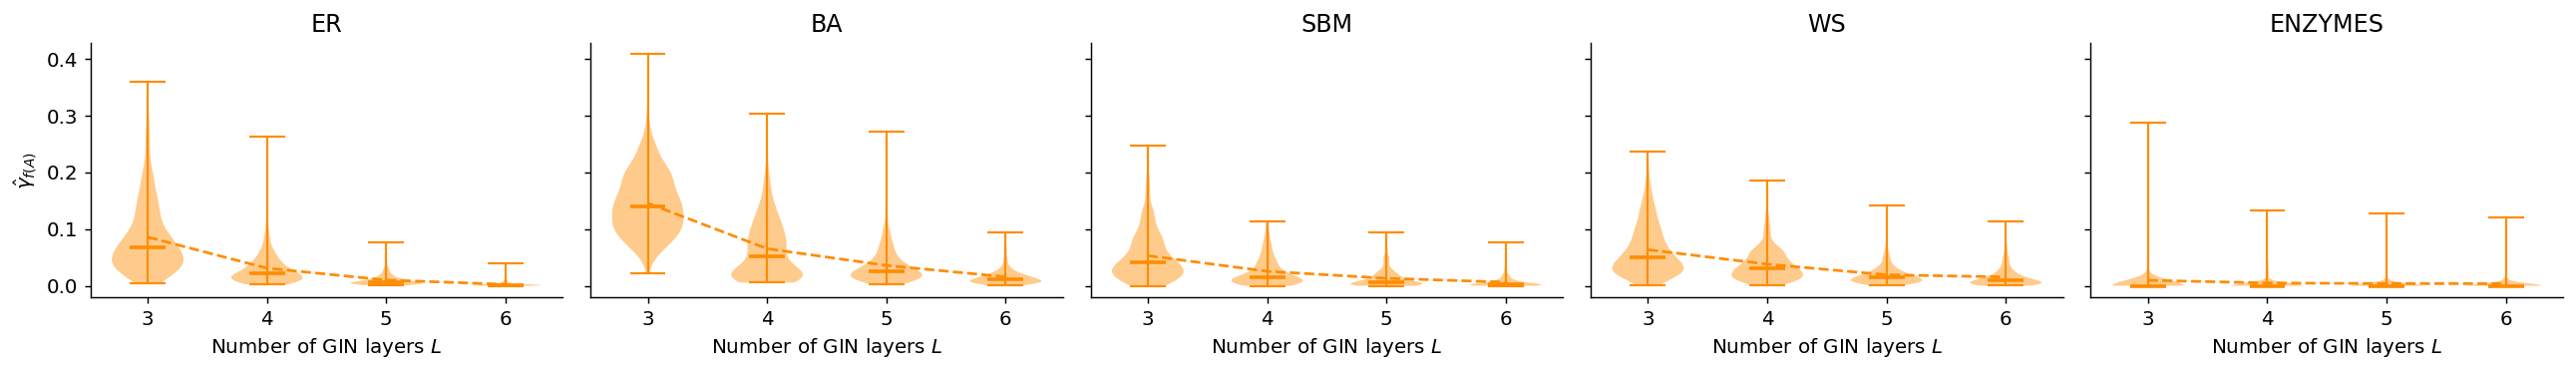

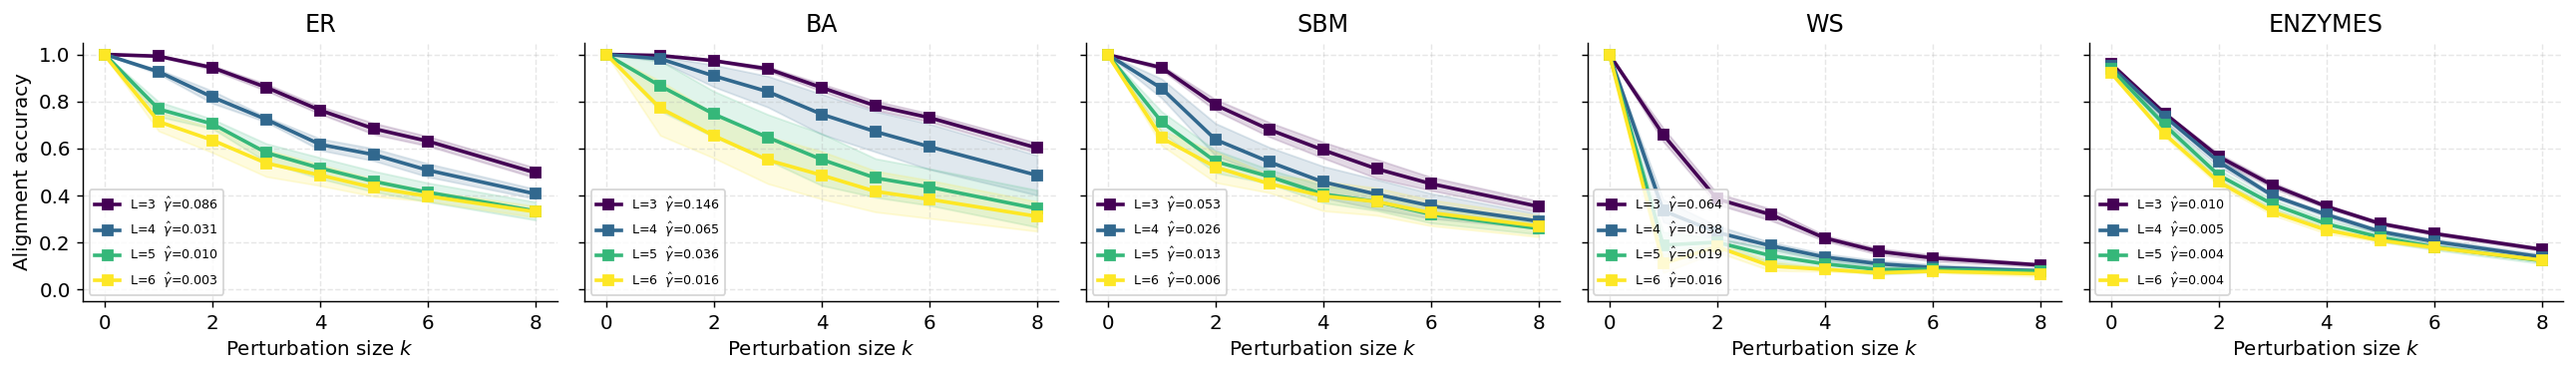

Saved: margin_GIN_ER.pdf, acc_GIN_ER.pdf, margin_GIN_BA.pdf, acc_GIN_BA.pdf, margin_GIN_SBM.pdf, acc_GIN_SBM.pdf, margin_GIN_WS.pdf, acc_GIN_WS.pdf, margin_GIN_ENZYMES.pdf, acc_GIN_ENZYMES.pdf


In [14]:
Ls    = DEPTH_VALUES
normL = plt.Normalize(vmin=min(Ls), vmax=max(Ls))
nG    = len(GRAPH_TYPES)

# --- Figure A: margin vs depth (violin, pooled across seeds), one panel per family ---
fig1, axes = plt.subplots(1, nG, figsize=(4 * nG, 3), sharey=True, squeeze=False)
axes = axes[0]
for ax, gt in zip(axes, GRAPH_TYPES):
    r          = depth_results[gt]
    gammas_d   = [r[L]['gamma_mean'] for L in Ls]
    gamma_data = [r[L]['gamma_all']  for L in Ls]
    parts = ax.violinplot(gamma_data, positions=Ls, widths=0.6, showmedians=True)
    parts['cmedians'].set_color('darkorange'); parts['cmedians'].set_linewidth(2)
    for pc in parts['bodies']:
        pc.set_facecolor('darkorange'); pc.set_alpha(0.45)
    for key in ('cbars', 'cmins', 'cmaxes'):
        parts[key].set_color('darkorange'); parts[key].set_linewidth(1.2)
    ax.plot(Ls, gammas_d, color='darkorange', linestyle='--')
    ax.set_xlabel(f'Number of {ARCH} layers $L$')
    ax.set_title(gt)
    ax.set_xticks(Ls)
axes[0].set_ylabel('$\\hat{\\gamma}_{f(A)}$')
fig1.tight_layout()
fig1.savefig(f'ALL_{ARCH.lower()}_depth_margin.pdf', bbox_inches='tight')
fig1.savefig(f'ALL_{ARCH.lower()}_depth_margin.png', bbox_inches='tight', dpi=150)
plt.show()

# --- Figure B: accuracy vs perturbation (mean ± std across seeds), one panel per family ---
fig2, axes = plt.subplots(1, nG, figsize=(4 * nG, 3), sharey=True, squeeze=False)
axes = axes[0]
for ax, gt in zip(axes, GRAPH_TYPES):
    for L in Ls:
        r  = depth_results[gt][L]
        ks = sorted(r['acc'].keys())
        means = np.array([r['acc'][k] for k in ks])
        stds  = np.array([r['acc_std'][k] for k in ks])
        color = CMAP_L(normL(L))
        ax.plot(ks, means, 's-', color=color, linewidth=2, markersize=5,
                label=f'L={L}  $\\hat{{\\gamma}}$={r["gamma_mean"]:.3f}')
        ax.fill_between(ks, means - stds, means + stds, color=color, alpha=0.15)
    ax.set_xlabel('Perturbation size $k$')
    ax.set_title(gt)
    ax.legend(fontsize=7, loc='lower left')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.3)
axes[0].set_ylabel('Alignment accuracy')
fig2.tight_layout()
fig2.savefig(f'ALL_{ARCH.lower()}_depth_acc_vs_k.pdf', bbox_inches='tight')
fig2.savefig(f'ALL_{ARCH.lower()}_depth_acc_vs_k.png', bbox_inches='tight', dpi=150)
plt.show()

# --- Individual figures per (model, data): saved as
#     margin_<model>_<data>.pdf  (margin vs depth, violin pooled across seeds)
#     acc_<model>_<data>.pdf     (accuracy vs perturbation, mean ± std across seeds)
for gt in GRAPH_TYPES:
    r = depth_results[gt]

    # Depth-margin plot
    f, ax = plt.subplots(figsize=(4, 3))
    gammas_d   = [r[L]['gamma_mean'] for L in Ls]
    gamma_data = [r[L]['gamma_all']  for L in Ls]
    parts = ax.violinplot(gamma_data, positions=Ls, widths=0.6, showmedians=True)
    parts['cmedians'].set_color('darkorange'); parts['cmedians'].set_linewidth(2)
    for pc in parts['bodies']:
        pc.set_facecolor('darkorange'); pc.set_alpha(0.45)
    for key in ('cbars', 'cmins', 'cmaxes'):
        parts[key].set_color('darkorange'); parts[key].set_linewidth(1.2)
    ax.plot(Ls, gammas_d, color='darkorange', linestyle='--')
    ax.set_xlabel(f'Number of {ARCH} layers $L$')
    ax.set_ylabel('$\\hat{\\gamma}_{f(A)}$')
    ax.set_xticks(Ls)
    # ax.set_title(f'{ARCH} + {gt}')
    f.tight_layout()
    f.savefig(f'margin_{ARCH}_{gt}.pdf', bbox_inches='tight')
    plt.close(f)

    # Accuracy vs perturbation plot
    f, ax = plt.subplots(figsize=(4, 3))
    for L in Ls:
        rl = r[L]
        ks = sorted(rl['acc'].keys())
        means = np.array([rl['acc'][k] for k in ks])
        stds  = np.array([rl['acc_std'][k] for k in ks])
        color = CMAP_L(normL(L))
        ax.plot(ks, means, 's-', color=color, linewidth=2, markersize=5,
                label=f'L={L}  $\\hat{{\\gamma}}$={rl["gamma_mean"]:.3f}')
        ax.fill_between(ks, means - stds, means + stds, color=color, alpha=0.15)
    ax.set_xlabel('Perturbation size $k$')
    ax.set_ylabel('Alignment accuracy')
    ax.legend(fontsize=8, loc='lower left')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.3)
    # ax.set_title(f'{ARCH} + {gt}')
    f.tight_layout()
    f.savefig(f'acc_{ARCH}_{gt}.pdf', bbox_inches='tight')
    plt.close(f)

print('Saved:', ', '.join(f'margin_{ARCH}_{gt}.pdf, acc_{ARCH}_{gt}.pdf' for gt in GRAPH_TYPES))

## 7. Summary Table

In [10]:
print(f'Values below are mean±std across {N_SEEDS} training seeds {SEEDS}.\n')

def fmt_pm(mean, std, decimals=3):
    return f"{mean:.{decimals}f}±{std:.{decimals}f}"

acc_ks = [0, 1, 2, 3, 4, 5, 6, 8]
col_w  = 13
hdr = f"{'Config':<20} {'gamma':>{col_w}} " + " ".join(f"{'acc@k='+str(k):>{col_w}}" for k in acc_ks)
print(hdr); print('─' * len(hdr))

for gt in GRAPH_TYPES:
    for L in DEPTH_VALUES:
        r         = depth_results[gt][L]
        gamma_str = fmt_pm(r['gamma_mean'], r['gamma_std'], decimals=4)
        acc_strs  = [fmt_pm(r['acc'].get(k, float('nan')), r['acc_std'].get(k, float('nan')))
                     for k in acc_ks]
        cfg = f"{gt}/{ARCH}/L={L}"
        row = f"{cfg:<20} {gamma_str:>{col_w}} " + " ".join(f"{s:>{col_w}}" for s in acc_strs)
        print(row)
    print()

Values below are mean±std across 5 training seeds [0, 1, 2, 3, 4].

Config                       gamma       acc@k=0       acc@k=1       acc@k=2       acc@k=3       acc@k=4       acc@k=5       acc@k=6       acc@k=8
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
ER/GIN/L=3           0.0859±0.0095   1.000±0.000   0.992±0.003   0.944±0.009   0.860±0.015   0.762±0.016   0.684±0.024   0.631±0.020   0.496±0.021
ER/GIN/L=4           0.0310±0.0050   1.000±0.000   0.926±0.010   0.818±0.026   0.723±0.011   0.617±0.024   0.574±0.026   0.508±0.028   0.407±0.021
ER/GIN/L=5           0.0101±0.0012   1.000±0.000   0.767±0.032   0.704±0.020   0.582±0.039   0.516±0.045   0.460±0.044   0.413±0.040   0.334±0.039
ER/GIN/L=6           0.0025±0.0006   0.996±0.004   0.714±0.040   0.635±0.053   0.537±0.057   0.487±0.045   0.433±0.037   0.397±0.022   0.331±0.024

BA/GIN/L=3           0.1457±0.0228   1.000±0.000 